In [1]:
from anemone.forwards import OnTimeForward, ForwardFlow
from anemone.system import *
import matplotlib.pyplot as plt
import numpy as np


In [4]:
tx = Loop.square(3)
rx = Receiver(x=10)
times = torch.logspace(-9, -2, 101)
wv = Waveform.example()
# wv.time[-1] /= 10.

fwr1 = ForwardFlow(tx, rx, times, waveform=wv)
fwr2 = OnTimeForward(tx, rx, times, waveform=wv, t_smp_per_decade=24)

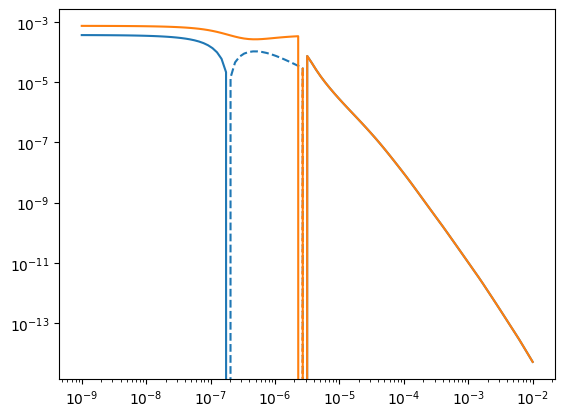

In [5]:
rho = torch.tensor([40, 20, 80])
thick = torch.tensor([10, 20])

dbdt1 = fwr1(rho, thick)
dbdt2 = fwr2(rho, thick)

plt.figure()
plt.loglog(times.numpy(), dbdt1)
plt.loglog(times.numpy(), -dbdt1, 'C0--')
plt.loglog(times.numpy(), dbdt2, 'C1')
plt.loglog(times.numpy(), -dbdt2, 'C1--')

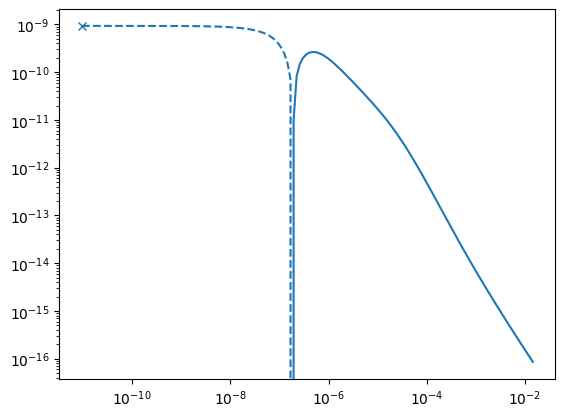

In [7]:
plt.figure()
plt.loglog(fwr2.t_in, fwr2.bstep.numpy()[1:])
plt.loglog(fwr2.t_in, -fwr2.bstep.numpy()[1:], 'C0--')
plt.loglog(fwr2.t_in.min(),  fwr2.bstep.numpy()[0], 'C0.')
plt.loglog(fwr2.t_in.min(), -fwr2.bstep.numpy()[0], 'C0x')